In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()
DATABASE_URL = os.getenv('DATABASE_URL')

if not DATABASE_URL:
    raise ValueError(
        'Empty DATABASE_URL, copy .env.example to your .env and make a database connection.'
    )

In [3]:
from sqlalchemy import create_engine, text

engine = create_engine(
    DATABASE_URL
)

with engine.connect() as connection:
    database_name = connection.execute(text("SELECT current_database()")).scalar_one()

print(database_name)

olist_analytics


In [4]:
from pathlib import Path

marker = "-- name: "
query_lines_by_name = {}
query_name = None

sql_path = Path("../sql/03_business_metrics.sql")
with sql_path.open(encoding="utf-8") as sql_file:
    for line in sql_file:
        if line.startswith(marker):
            query_name = line.removeprefix(marker).strip()
            query_lines_by_name[query_name] = []
        elif query_name is not None:
            query_lines_by_name[query_name].append(line)

queries_by_name = {
    name: "".join(lines)
    for name, lines in query_lines_by_name.items()
}

## Динамика продаж

Сравниваем по месяцу покупки число доставленных заказов, стоимость товаров и средний чек по стоимости товаров. Денежные показатели выражены в бразильских реалах (BRL).

In [5]:
with engine.connect() as conn, conn.begin():
    monthly_sales = pd.read_sql_query(
        queries_by_name["monthly_sales"],
        conn
    )

In [6]:
monthly_sales.head()

,purchase_month,delivered_order_count,delivered_items_total,avg_delivered_order_items_total
0,2016-09-01,1,134.97,134.970000
1,2016-10-01,265,40325.11,152.170226
2,2016-12-01,1,10.90,10.900000
3,2017-01-01,750,111798.36,149.064480
4,2017-02-01,1653,234223.40,141.695947


In [7]:
expected_months = pd.date_range(
    start=monthly_sales['purchase_month'].min(), 
    end=monthly_sales['purchase_month'].max(),
    freq='MS',
    name='purchase_month'
)

In [8]:
expected_months.difference(monthly_sales['purchase_month'])

DatetimeIndex(['2016-11-01'], dtype='datetime64[us]', name='purchase_month',
              freq='MS')

### Период сравнения

На графиках продаж и доставки используем 19 месяцев с февраля 2017 по август 2018 включительно. По данным `public.orders` в каждом из этих месяцев хотя бы один заказ любого статуса был оформлен в каждый календарный день. В январе 2017 заказы есть в 27 из 31 дня, а в ноябре 2016 записей нет. Покрытие по дням помогает выбрать период для сравнения, но само по себе не подтверждает полноту данных.

In [9]:
monthly_sales_comparable = monthly_sales.query("purchase_month >= '2017-02-01' and purchase_month < '2018-09-01'")

Text(0.5, 0, 'Месяц покупки')

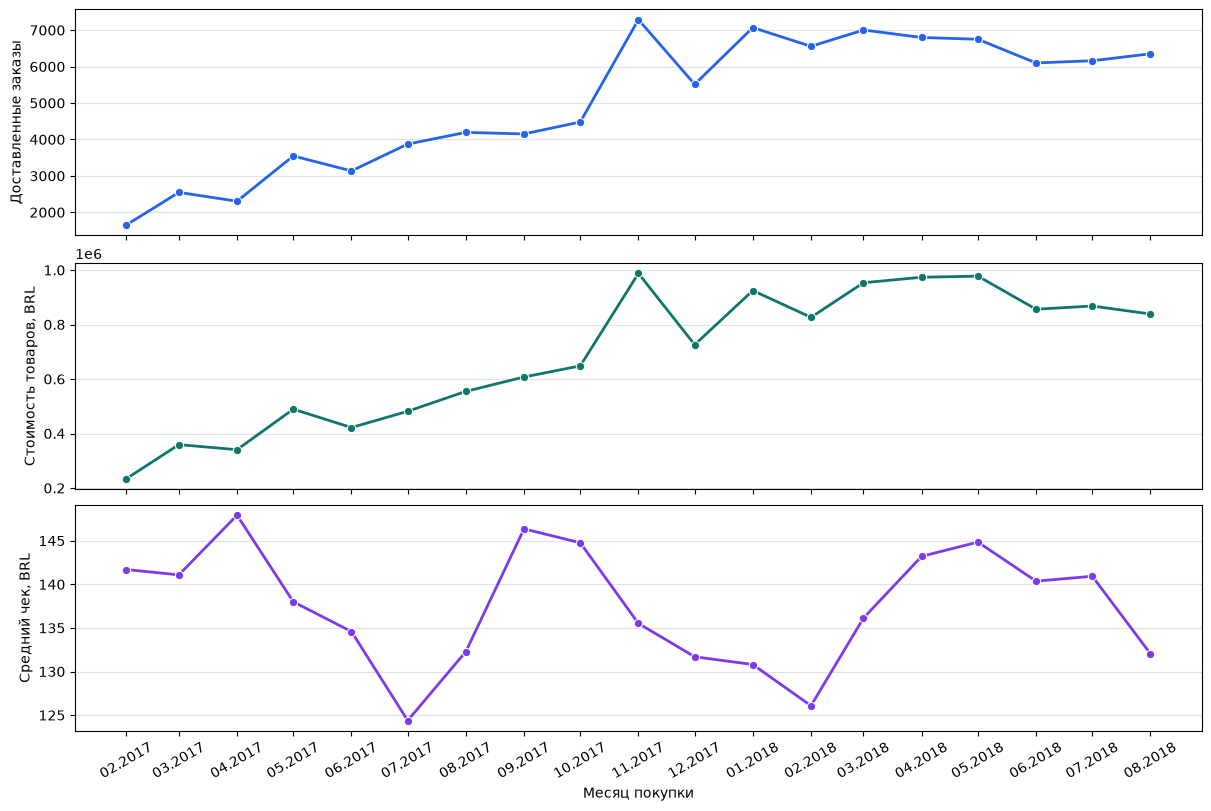

In [10]:
import matplotlib.dates as mdates

fig, axes = plt.subplots(
    3, 1, 
    sharex=True,
    figsize=(12, 8),
    layout='constrained'
)

sns.lineplot(
    data=monthly_sales_comparable,
    x='purchase_month',
    y='delivered_order_count',
    color='#2563EB',
    marker='o',
    linewidth=2,
    ax=axes[0]
)

sns.lineplot(
    data=monthly_sales_comparable,
    x='purchase_month',
    y='delivered_items_total',
    color="#0F766E",
    marker='o',
    linewidth=2,
    ax=axes[1]
)
sns.lineplot(
    data=monthly_sales_comparable,
    x='purchase_month',
    y='avg_delivered_order_items_total',
    color='#7C3AED',
    marker='o',
    linewidth=2,
    ax=axes[2]
)

for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#D1D5DB", linewidth=0.8, alpha=0.7)

axes[0].set_ylabel('Доставленные заказы')
axes[1].set_ylabel('Стоимость товаров, BRL')
axes[2].set_ylabel('Средний чек, BRL')

axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=1))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))
axes[-1].tick_params(axis="x", labelrotation=30)
axes[-1].set_xlabel("Месяц покупки")

In [11]:
month_comparison = (monthly_sales
    .set_index('purchase_month')
    .query("purchase_month >= '2017-10-01' and purchase_month <= '2017-11-01'")
    .sort_index()
)

month_over_month_pct = month_comparison.pct_change().mul(100).round(2)

month_comparison

,delivered_order_count,delivered_items_total,avg_delivered_order_items_total
purchase_month,,,
2017-10-01,4478,648247.65,144.762762
2017-11-01,7289,987765.37,135.514525


In [12]:
month_over_month_pct

,delivered_order_count,delivered_items_total,avg_delivered_order_items_total
purchase_month,,,
2017-10-01,NaN,NaN,NaN
2017-11-01,62.77,52.37,-6.39


С октября по ноябрь 2017 года стоимость товаров выросла на 52,37%. Число доставленных заказов выросло на 62,77%, перекрыв снижение среднего чека на 6,39%. Стоимость товаров выросла за счет увеличения числа доставленных заказов, несмотря на снижение среднего чека.

## Опоздания доставки

Сравниваем по месяцу покупки число доставок с известным признаком опоздания и доли опоздавших заказов.

In [13]:
with engine.connect() as conn, conn.begin():
    monthly_delivery = pd.read_sql_query(
        queries_by_name["monthly_delivery"],
        conn
    )

In [14]:
monthly_delivery_comparable = (
    monthly_delivery
    .query("purchase_month >= '2017-02-01' and purchase_month < '2018-09-01'")
)

In [15]:
monthly_delivery_comparable.head()

,purchase_month,delivered_order_count,known_lateness_count,unknown_lateness_count,delivered_late_count,late_order_pct
0,2017-07-01,3872,3872,0,108,2.79
1,2018-05-01,6749,6749,0,443,6.56
2,2018-07-01,6159,6156,3,208,3.38
4,2018-08-01,6351,6351,0,393,6.19
5,2018-02-01,6555,6555,0,926,14.13


Text(0.5, 0, 'Месяц покупки')

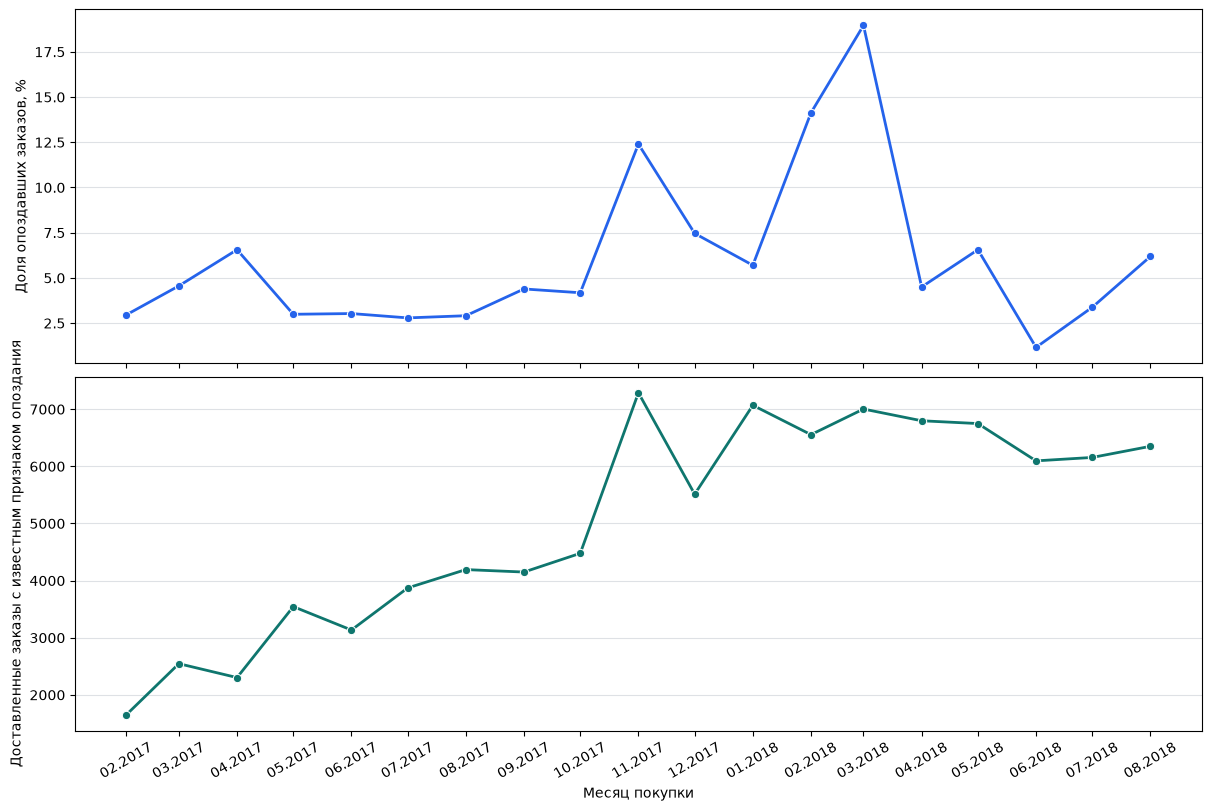

In [16]:
fig, axes = plt.subplots(
    2, 1, 
    sharex=True,
    figsize=(12, 8),
    layout='constrained'
)

sns.lineplot(
    data=monthly_delivery_comparable,
    x='purchase_month',
    y='late_order_pct',
    color='#2563EB',
    marker='o',
    linewidth=2,
    ax=axes[0]
)

sns.lineplot(
    data=monthly_delivery_comparable,
    x='purchase_month',
    y='known_lateness_count',
    color="#0F766E",
    marker='o',
    linewidth=2,
    ax=axes[1]
)

for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#D1D5DB", linewidth=0.8, alpha=0.7)

axes[0].set_ylabel('Доля опоздавших заказов, %')
axes[1].set_ylabel('Доставленные заказы с известным признаком опоздания')

axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=1))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))
axes[-1].tick_params(axis="x", labelrotation=30)
axes[-1].set_xlabel("Месяц покупки")

С февраля по март 2018 года доля опозданий выросла с 14,13% до 18,96%. Число опозданий выросло с 926 до 1 328, а число заказов, вошедших в расчёт, — с 6 555 до 7 003. Доля выросла, потому что число опозданий росло быстрее числа заказов в расчёте.